In [ ]:
import matplotlib as mpl
import matplotlib.collections as mcollections
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as signal

We quantify the similarities between bottom-near and surface variables by the normalized cross-correlation between two time series $a(t)$ and $b(t)$ as $\big(a \star b\big)(t^\prime)$, building on an implementation in Scipy.
$\big(a \star b\big)(t^\prime)$ is then given as
\begin{equation}
    \big(a \star b\big)(t^\prime) \overset{\text{def}}= \int_{-\infty}^{\infty} \frac{\big(a(t)-\mu_a\big) \: \big(b(t-t^\prime)-\mu_b\big)}{\sigma_a\sigma_b} \: \mathrm{d}t,
\end{equation}
with the temporal arithmetic means $\mu_a, \mu_b$ and standard deviations $\sigma_a, \sigma_b$ of the two time series.
The time lag $t^\prime$ describes the shift of one time series against another.
A positive lag $t^\prime$ means time series $a$ lags time series $b$ (i.e., the peaks in $b$ happen first).

The normalization ensures the cross-correlation at zero lag is equal to the linear correlation coefficient and through that the comparability between multiple cross-correlations.
We approximate the uncertainty of the correlation at every lag $∆ {(a \star b)}(t^\prime)$ by the standard error of the linear correlation coefficient, dependent on the degrees of freedom $n-3$ and the number of data points $n$ in the time series (Gnambs et al., 2023, Bonett et al., 2008)
\begin{equation}
   ∆ {(a \star b)}(t^\prime) = \frac{1-\Big[\big(a \star b\big)(t^\prime)\Big]^2}{\sqrt{n-3}}.
\end{equation}

### Computation functions

In [ ]:
def get_normalized_crosscorr(a, b):
    assert len(a) == len(b)
    n = len(a)

    lags = signal.correlation_lags(len(a), len(b), mode="same")
    c = signal.correlate(a - a.mean(), b - b.mean(), "same") / (np.std(a * np.std(b)))
    cross_correlation = c / n
    return lags, cross_correlation


def get_crosscorr_standard_error(corr, N):
    # standard error of pearson correlation according to Bonett2008, recommended in Gnambs2023
    standard_error = (1 - corr**2) / np.sqrt(N - 3)
    return standard_error

### Plotting functions

In [3]:
def plot_xy_errorbands(
    x,
    y,
    x_errors,
    y_errors,
    x_style: dict | None = None,
    y_style: dict | None = None,
    x_label: str = "",
    y_label: str = "",
    plot_errorbars: bool = False,
    ax: mpl.axes.Axes = None,
):

    if y_style is None:
        y_style = {}
    if x_style is None:
        x_style = {}
    x_lower = x - x_errors
    x_upper = x + x_errors
    y_lower = y - y_errors
    y_upper = y + y_errors

    if ax is None:
        fig, ax = plt.subplots(1)

    # Build a list of quads between consecutive points
    verts = [
        [
            (x_upper[i], y[i]),
            (x_upper[i + 1], y[i + 1]),
            (x_lower[i + 1], y[i + 1]),
            (x_lower[i], y[i]),
        ]
        for i in range(len(x) - 1)
    ]

    poly = mcollections.PolyCollection(verts, **x_style)
    ax.add_collection(poly)

    ax.fill_between(x, y_lower, y_upper, **y_style, label=y_label)


def plot_corr_with_error_bands(lags, corr, x_err, y_err, axis, label, color):
    y_style = {"hatch": "||||", "facecolor": "None", "linewidth": 0}
    x_style = {"hatch": "---", "facecolor": "None", "linewidth": 0}
    x_style["edgecolor"] = color
    y_style["edgecolor"] = color
    plot_xy_errorbands(lags, corr, x_err, y_err, x_style, y_style, ax=axis)
    axis.plot(lags, corr, color=color, label=label, lw=2.5)

### Example

In [4]:
def f(x, shift):
    x = np.asarray(x)
    x_noise = np.random.normal(-0.1, 0.1, size=x.shape)
    y_noise = np.random.normal(-0.1, 0.1, size=x.shape)
    return 1 / ((x - (shift + x_noise)) ** 2 + 0.2) + y_noise


x = np.arange(-10, 10, 0.1)
a = f(x, 0)

shift = -5
b = 2 * f(x, shift)

lags, cross_correlation = get_normalized_crosscorr(a, b)
lag_time_step_in_days = 0.1
time_lags = lags * lag_time_step_in_days

time_err = 0.5  # just assumed here
corr_err = get_crosscorr_standard_error(
    corr=cross_correlation, N=len(a)
)  # assumes a and b are of the same length

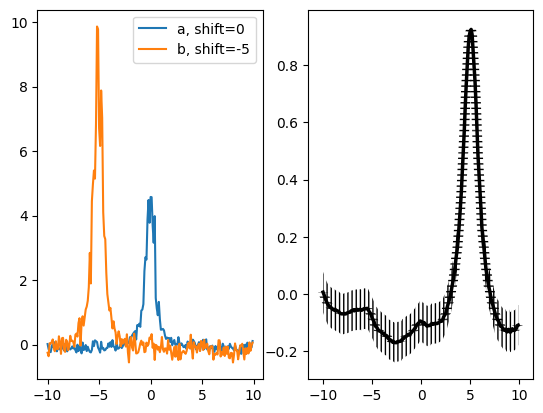

In [ ]:
fig, ax = plt.subplots(ncols=2)

ax[0].plot(x, a, label="a, shift=0")
ax[0].plot(x, b, label=f"b, {shift=}")
ax[0].legend()
plot_corr_with_error_bands(
    time_lags, cross_correlation, time_err, corr_err, axis=ax[1], label="", color="black"
)

> A positive lag $t^\prime$ means time series $a$ lags time series $b$ (i.e., the peaks in $b$ happen first).